<a href="https://colab.research.google.com/github/jason-zermani/A05-pca/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('/content/sample_data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

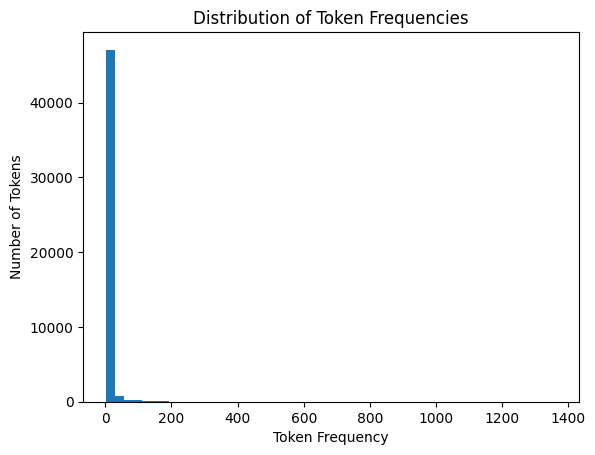

In [ ]:
import matplotlib.pyplot as plt

frequencies = [count for word, count in token_freq]

plt.hist(frequencies, bins=50)
plt.xlabel('Token Frequency')
plt.ylabel('Number of Tokens')
plt.title('Distribution of Token Frequencies')
plt.show()

Histogram is right skewed. Most tokens appear only a few times, some appear much more frequently

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet('/content/sample_data/Phishing_clean.parquet')

X = df.drop('Email Type', axis=1)
y = df['Email Type']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()

model.fit(X_train, y_train)

print("Training R-squared:", model.score(X_train, y_train))
print("Test R-squared:", model.score(X_test, y_test))

Training R-squared: 0.7670143724934355
Test R-squared: 0.6658718438847919


In [ ]:
coefficients = pd.Series(model.coef_, index=X.columns)

print("Largest positive coefficients:")
print(coefficients.sort_values(ascending=False).head(10))

print("Largest negative coefficients:")
print(coefficients.sort_values().head(10))

print("Largest coefficients by absolute value:")
print(coefficients.abs().sort_values(ascending=False).head(10))

Largest positive coefficients:
localized            0.824350
thermal              0.747006
crawler              0.696167
helvetica,           0.598560
aging                0.594956
form.                0.576886
a:active             0.574480
{text-decoration:    0.497075
xanaax               0.491981
transcript           0.488978
dtype: float64
Largest negative coefficients:
intervention        -1.259257
background-image:   -0.622909
gray;               -0.574480
retrieving          -0.573761
zdnet               -0.560954
shopper             -0.486678
april's             -0.486483
arial,              -0.482141
issue:              -0.465547
cnet                -0.453777
dtype: float64
Largest coefficients by absolute value:
intervention         1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:    0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;                0.57448

Test 𝑅2 shows how well the model predicts scam emails in the test data. Training 𝑅2 shows how well the model fits the training data.

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

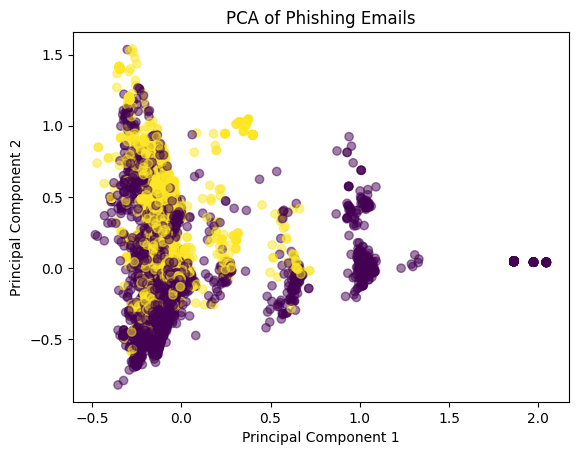

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

X = df.drop('Email Type', axis=1)
y = df['Email Type']

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, alpha=0.5)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Phishing Emails')
plt.show()

The plot shows overlap between phishing and non-phishing emails. The two groups are not fully separated. The first two principal components capture some differences between emails, but they are not enough to differentiate phishing scams from legitimate emails.

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [ ]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

X = df.drop('Email Type', axis=1)
y = df['Email Type']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pca = PCA(n_components=2610)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train)

print("Training R-squared:", model_pca.score(X_train_pca, y_train))
print("Test R-squared:", model_pca.score(X_test_pca, y_test))

Training R-squared: 0.7662326827745849
Test R-squared: 0.6683390643101164


Original: Training R-squared: 0.7670143724934355
Test R-squared: 0.6658718438847919
PCA: Training R-squared: 0.7662326827745849
Test R-squared: 0.6683390643101164

Similar performances, PCA was slightly better

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

Using principal components simplifies the data by combining related words into fewer features, making the model easier to work with and making the predictions better.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [ ]:
# Your Phase 1 solution to the problem goes here.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

In [ ]:
import pickle

with open('/content/sample_data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

print("First 20 tokens:")
print(all_tokens[:20])

print("Total number of tokens:", len(all_tokens))

First 20 tokens:
['1100', 'disc', 'uniformitarianism', '1086', 'sex', 'lang', 'dick', 'hudson', 'observations', 'use', 'side', 'galicismos', 'galicismo', 'spanish', 'term', 'names', 'improper', 'introduction', 'french', 'words']
Total number of tokens: 276949


In [ ]:
from collections import Counter

token_count = Counter(all_tokens)

token_freq = token_count.most_common()

print("Number of unique tokens:", len(token_count))

print("20 most common tokens:")
for word, count in token_freq[:20]:
    print(word, ":", count)

Number of unique tokens: 48691
20 most common tokens:
new : 1365
date : 1202
get : 1052
please : 1022
enron : 927
like : 923
2002 : 869
would : 806
one : 798
message : 795
call : 740
free : 691
software : 680
dear : 651
know : 644
email : 629
url: : 625
time : 609
start : 604
linguistics : 598


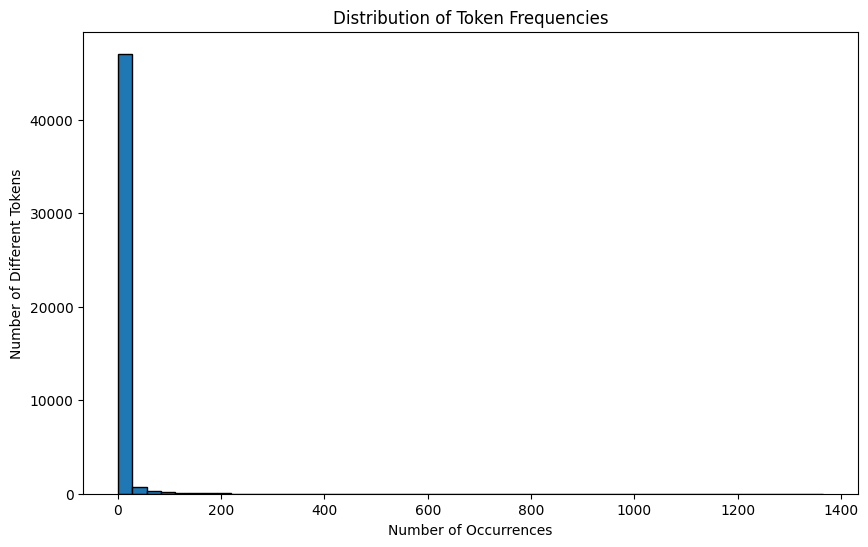

In [ ]:
import matplotlib.pyplot as plt

frequencies = []

for word, count in token_freq:
    frequencies.append(count)

plt.figure(figsize=(10, 6))

plt.hist(frequencies, bins=50, edgecolor='black')

plt.xlabel('Number of Occurrences')
plt.ylabel('Number of Different Tokens')
plt.title('Distribution of Token Frequencies')

plt.show()

In [ ]:
print("10 most frequent tokens:")
print(token_freq[:10])

print("10 least frequent tokens:")
print(token_freq[-10:])

print("Most frequent token:", token_freq[0])

10 most frequent tokens:
[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]
10 least frequent tokens:
[('machine-readable', 1), ('four-letter', 1), ('giancola', 1), ('http://diveintomark.org/archives/2002/09/25.html#plan', 1), ('2002-09-25t10:43:06-05:00_paul', 1), ('truck[1].', 1), ('feet,', 1), ('housewifes', 1), ('dorn', 1), ('clippings', 1)]
Most frequent token: ('new', 1365)


The frequency of token occurrence is heavily right-skewed. Most tokens appear relatively few times, while a small number of tokens appear much more frequently. The histogram has a tall bar on the left and a long tail extending to the right. This shows that word usage is not evenly distributed across the emails, even after punctuation and common words have been removed.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet('/content/sample_data/Phishing_clean.parquet')

print("First five rows:")
print(df.head())

print("Dataset size:")
print(df.shape)

print("Column names:")
print(df.columns.tolist())

First five rows:
   Email Type  new  date  get  please  enron  like  2002  would  one  ...  \
0           0    0     0    0       0      0     0     0      0    0  ...   
1           0    0     0    0       0      0     0     0      0    0  ...   
2           0    1     0    0       0      0     0     0      0    0  ...   
3           1    0     0    0       0      0     0     0      0    1  ...   
4           1    0     0    0       0      0     0     0      0    0  ...   

   ï¿½ï¿½  safety  yap  ypil  maintain  procedures  tip  elizabeth  \
0       0       0    0     0         0           0    0          0   
1       0       0    0     0         0           0    0          0   
2       0       0    0     0         0           0    0          0   
3       0       0    0     0         0           0    0          0   
4       0       0    0     0         0           0    0          0   

   leadership  italian  
0           0        0  
1           0        0  
2           0        0  

In [ ]:
X = df.drop('Email Type', axis=1)
y = df['Email Type']

print("Number of email features:", X.shape[1])
print("Number of emails:", X.shape[0])

print("Email type counts:")
print(y.value_counts())

Number of email features: 2711
Number of emails: 18634
Email type counts:
Email Type
0    11322
1     7312
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training emails:", X_train.shape[0])
print("Testing emails:", X_test.shape[0])

Training emails: 14907
Testing emails: 3727


In [ ]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model training complete.")

Model training complete.


In [ ]:
train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)

print("Training R-squared:", train_r2)
print("Test R-squared:", test_r2)

Training R-squared: 0.7670143724934355
Test R-squared: 0.6658718438847919


In [ ]:
coefficients = pd.Series(model.coef_, index=X.columns)

print("10 largest positive coefficients:")
print(coefficients.sort_values(ascending=False).head(10))

print("10 largest negative coefficients:")
print(coefficients.sort_values().head(10))

print("10 largest coefficients by absolute value:")
print(coefficients.abs().sort_values(ascending=False).head(10))

10 largest positive coefficients:
localized            0.824350
thermal              0.747006
crawler              0.696167
helvetica,           0.598560
aging                0.594956
form.                0.576886
a:active             0.574480
{text-decoration:    0.497075
xanaax               0.491981
transcript           0.488978
dtype: float64
10 largest negative coefficients:
intervention        -1.259257
background-image:   -0.622909
gray;               -0.574480
retrieving          -0.573761
zdnet               -0.560954
shopper             -0.486678
april's             -0.486483
arial,              -0.482141
issue:              -0.465547
cnet                -0.453777
dtype: float64
10 largest coefficients by absolute value:
intervention         1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:    0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;              

In [ ]:
coefficient_table = pd.DataFrame({
    'Word': X.columns,
    'Coefficient': model.coef_,
    'Absolute Coefficient': np.abs(model.coef_)
})

coefficient_table = coefficient_table.sort_values(
    by='Absolute Coefficient',
    ascending=False
)

print(coefficient_table.head(20))

                   Word  Coefficient  Absolute Coefficient
835        intervention    -1.259257              1.259257
740           localized     0.824350              0.824350
2362            thermal     0.747006              0.747006
851             crawler     0.696167              0.696167
1504  background-image:    -0.622909              0.622909
1406         helvetica,     0.598560              0.598560
906               aging     0.594956              0.594956
1839              form.     0.576886              0.576886
2242              gray;    -0.574480              0.574480
1552           a:active     0.574480              0.574480
1494         retrieving    -0.573761              0.573761
2657              zdnet    -0.560954              0.560954
1245  {text-decoration:     0.497075              0.497075
2532             xanaax     0.491981              0.491981
2566         transcript     0.488978              0.488978
2639            shopper    -0.486678              0.4866

The linear regression model achieved a training \(R^2\) of approximately 0.767 and a test \(R^2\) of approximately 0.666. This means the model explains about 76.7% of the variation in the training data and 66.6% in the test data. The words with the largest absolute coefficients have the strongest influence on the model's predictions. Positive and negative coefficients indicate different directions of association with the email type, depending on how the target is encoded. The difference between the training and test scores suggests that the model performs somewhat better on the data it was trained on than on new emails.

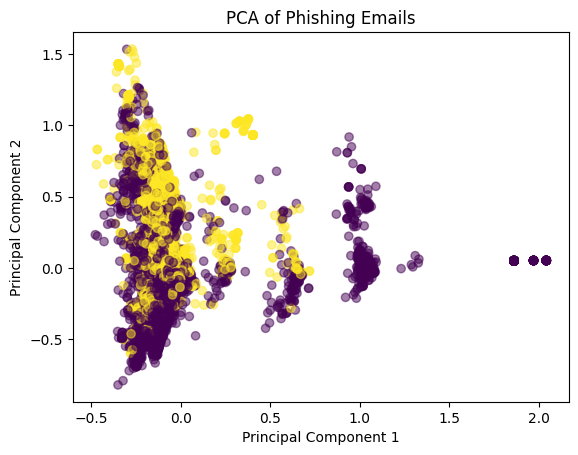

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

X = df.drop('Email Type', axis=1)
y = df['Email Type']

pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X)

plt.scatter(X_pca_2[:, 0], X_pca_2[:, 1], c=y, alpha=0.5)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Phishing Emails')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

X = df.drop('Email Type', axis=1)
y = df['Email Type']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

pca = PCA(n_components=2610)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train)

print("Training R-squared:", model_pca.score(X_train_pca, y_train))
print("Test R-squared:", model_pca.score(X_test_pca, y_test))

Training R-squared: 0.7662326827745849
Test R-squared: 0.6683390643101164


What does the PCA plot show?

The plot shows overlap between phishing and non-phishing emails, meaning the first two principal components do not clearly separate the two groups.

How does PCA regression compare to the original regression?

The original model had a training \(R^2\) of 0.767 and a test \(R^2\) of 0.666. The PCA model had a training \(R^2\) of 0.766 and a test \(R^2\) of 0.668. Both performed similarly, but PCA performed slightly better on the test data.

What is the advantage of PCA?

PCA combines related features into new components, simplifying high-dimensional data and potentially reducing noise and redundancy. Here, it maintained nearly the same predictive performance as the original model.

In [ ]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

X = df.drop('Email Type', axis=1)
y = df['Email Type']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

pca = PCA(n_components=2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train)

print("Training R-squared:", model_pca.score(X_train_pca, y_train))
print("Test R-squared:", model_pca.score(X_test_pca, y_test))

Training R-squared: 0.7662326827745849
Test R-squared: 0.6683390643101164


The PCA regression had a training \(R^2\) of 0.766 and a test \(R^2\) of 0.668. The original linear regression had a training \(R^2\) of 0.767 and a test \(R^2\) of 0.666. Both models performed very similarly, but PCA performed slightly better on the test set and slightly worse on the training set.

Using principal components simplifies the data by combining related words into fewer features. This makes the regression easier to manage and can reduce noise and redundancy. In this case, both models performed about the same, but PCA did slightly better on the test data.

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The AI helped me by verifying my solutions and distinguishing each part of each question step by step, including some steps that I didn't include. It made all my solutions in depth, and it also took all of my written answers and either changed the wording or added a lot to my answers
